# w1 · XGBoost + Importance Reweighting · Manual segment (KKBox churn)

Applies **covariate shift correction** to XGBoost to correct the February → March
distribution drift.  Uses the 48-feature subset of the w1 manual parquet (59 features
minus 11 low-signal features).

The drift root cause: `>31d` plan users churn at 82.7 % in March vs 49.0 % in
February, so their churner rows receive up-weight during training.

| Setting | Value |
|---|---|
| Features | 48 (w1 manual parquet − 11 dropped) |
| Reweighting | >31d churn ×1.69 · <=31d churn ×1.085 · non-churn ×1.0 |
| Model | XGBClassifier with early stopping |

**w1_manual M3 reference** (same features, no reweighting):
AUC = 0.7784 · AP = 0.7195 · log-loss = 0.5632 · F1 = 0.6757

## 0. Setup

In [1]:
import sys
import json
import warnings
import numpy as np
import pandas as pd
import polars as pl
import matplotlib.pyplot as plt
import sklearn
import xgboost
import joblib
from datetime import date
from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    log_loss, roc_auc_score, average_precision_score, brier_score_loss,
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, matthews_corrcoef, confusion_matrix,
    precision_recall_curve, roc_curve,
)
from xgboost import XGBClassifier
warnings.filterwarnings('ignore')

HERE = Path.cwd().resolve()
ROOT = None
for _p in [HERE, *HERE.parents]:
    if (_p / 'eda' / '_common.py').exists():
        ROOT = _p
        sys.path.insert(0, str(_p / 'eda'))
        break
if ROOT is None:
    raise FileNotFoundError('Cannot find workshops/eda/_common.py')
import _common as C

W1_DIR    = ROOT / 'w1' / 'export-tabular-v5'
FIGS_DIR  = ROOT / 'w1' / 'figures' / 'eda_manual_reweighting'
FIGS_DIR.mkdir(parents=True, exist_ok=True)

FEB_CUTOFF = date(2017, 1, 31)
MAR_CUTOFF = date(2017, 2, 28)

print(f'ROOT:     {ROOT}')
print(f'W1_DIR:   {W1_DIR}')
print(f'FIGS_DIR: {FIGS_DIR}')

ROOT:     C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops
W1_DIR:   C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\export-tabular-v5
FIGS_DIR: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\figures\eda_manual_reweighting


## 1. Configuration

Same XGB hyperparameters as `w1_manual_tabular_models` M3 (lr=0.1, max_depth=6).
Same preprocessor (OHE + median imputation + StandardScaler).

Reweighting weights: `P_mar(churn | seg) / P_feb(churn | seg)` per plan segment.
Non-churners fixed at 1.0.

The 11 dropped features were identified as low-signal in earlier ablation experiments.

In [2]:
SEED = C.SEED

XGB_N_ESTIMATORS = 3000
XGB_LR           = 0.1
XGB_MAX_DEPTH    = 6
XGB_MIN_CHILD_W  = 3
XGB_COLSAMPLE    = 0.8
XGB_SUBSAMPLE    = 0.8
XGB_EARLY_STOP   = 100

PLAN_THR  = 31
W_CHURN   = {'>31d': 0.827 / 0.490, '<=31d': 0.295 / 0.272}  # ≈ 1.69, 1.085
W_NOCHURN = 1.0

CAT = ['city', 'registered_via', 'last_payment_method_id']

_NUM_59 = [
    'bd', 'bd_missing', 'tenure_days', 'registration_year', 'registration_month',
    'has_member_record', 'is_cancel_change_flag', 'is_auto_renew_change_flag',
    'transaction_count', 'average_amount_paid', 'average_amount_charged',
    'average_plan', 'n_payment_methods', 'n_plans', 'n_list_prices', 'n_amounts_paid',
    'duration', 'plan_coverage_ratio', 'sum_plan_days', 'sum_list_price',
    'sum_amount_paid', 'more_than_30', 'autorenew_not_cancel', 'not_autorenew_cancel',
    'max_plan_days', 'last_plan_days', 'last_is_auto_renew', 'last_is_cancel',
    'last_discount', 'days_to_expire', 'expire_dayofweek', 'days_since_last_transaction',
    'difference', 'has_transactions',
    'sum_last_month_unq', 'sum_last_month_total_secs', 'mean_last_month_total_secs',
    'last_login', 'last_sum_total_songs', 'last_ratio_100', 'last_ratio_25',
    'sum_last_second_month_total_secs', 'last_second_login',
    'last_second_sum_total_songs', 'last_second_ratio_100', 'last_second_ratio_25',
    'last_third_sum_total_songs', 'last_third_ratio_100', 'last_third_ratio_25',
    'login_difference', 'trend_songs', 'trend_secs', 'trend_ratio100', 'trend_ratio25',
    'days_since_last_log', 'has_listening_logs',
]
_DROP = {
    'has_transactions', 'last_is_cancel', 'autorenew_not_cancel', 'not_autorenew_cancel',
    'last_is_auto_renew', 'is_auto_renew_change_flag', 'is_cancel_change_flag',
    'last_discount', 'bd_missing', 'expire_dayofweek', 'n_amounts_paid',
}
NUM      = [f for f in _NUM_59 if f not in _DROP]
FEATURES = CAT + NUM

DISPLAY_COLUMNS = [
    'model_id', 'tune_log_loss', 'log_loss', 'roc_auc', 'average_precision',
    'brier', 'accuracy', 'balanced_accuracy', 'precision_churn', 'recall_churn',
    'specificity', 'f1_churn', 'f1_macro', 'mcc', 'threshold',
]

print(f'features: {len(CAT)} cat + {len(NUM)} num = {len(FEATURES)} total (dropped {len(_DROP)})')
print(f'W_CHURN: { {k: round(v,3) for k,v in W_CHURN.items()} }')
print(f'XGB: up to {XGB_N_ESTIMATORS} rounds, early stop {XGB_EARLY_STOP}, lr={XGB_LR}')

features: 3 cat + 45 num = 48 total (dropped 11)
W_CHURN: {'>31d': 1.688, '<=31d': 1.085}
XGB: up to 3000 rounds, early stop 100, lr=0.1


## 2. Data loading

Both February and March cohorts are filtered to `state='manual'` (users whose last
payment was not auto-renewed).  `plan_seg_feb` is added to February for the
reweighting weights; `plan_seg` is added to March for the segment breakdown.

In [3]:
C.set_cutoff(FEB_CUTOFF)
cohort     = C.load_cohort()
_users_feb = cohort.select('msno', 'is_churn')
txn_feb    = C.clean_transactions(_users_feb)
state_feb  = C.subscription_state(txn_feb, _users_feb)

state_map_feb = dict(zip(state_feb['msno'].to_list(), state_feb['state'].to_list()))
split_map     = dict(zip(cohort['msno'].to_list(),    cohort['split'].to_list()))

feb_raw          = pd.read_parquet(W1_DIR / 'train_feb.parquet')
feb_raw['state'] = feb_raw['msno'].map(state_map_feb)
feb_raw['split'] = feb_raw['msno'].map(split_map)
feb_m            = feb_raw[feb_raw['state'] == 'manual'].copy()

plan_map_feb = dict(zip(state_feb['msno'].to_list(), state_feb['last_plan_days'].to_list()))
feb_m['plan_seg_feb'] = (
    feb_m['msno'].map(plan_map_feb).fillna(0).gt(PLAN_THR)
    .map({True: '>31d', False: '<=31d'})
)

print(f'Feb: {len(feb_raw):,} total → {len(feb_m):,} manual '
      f'({len(feb_m)/len(feb_raw):.1%}) | churn: {feb_m["is_churn"].mean():.2%}')

Feb: 992,931 total → 110,846 manual (11.2%) | churn: 31.78%


In [4]:
C.set_cutoff(MAR_CUTOFF)
mar_users     = pl.read_parquet(C.PARQUET_DIR / 'train_v2.parquet', columns=['msno', 'is_churn'])
txn_mar       = C.clean_transactions(mar_users)
state_mar     = C.subscription_state(txn_mar, mar_users)
state_map_mar = dict(zip(state_mar['msno'].to_list(), state_mar['state'].to_list()))

mar_raw          = pd.read_parquet(W1_DIR / 'test.parquet')
mar_raw['state'] = mar_raw['msno'].map(state_map_mar)
test_df          = mar_raw[mar_raw['state'] == 'manual'].copy()

plan_map_mar = dict(zip(state_mar['msno'].to_list(), state_mar['last_plan_days'].to_list()))
test_df['plan_seg'] = (
    test_df['msno'].map(plan_map_mar).fillna(0).gt(PLAN_THR)
    .map({True: '>31d', False: '<=31d'})
)
C.set_cutoff(FEB_CUTOFF)

print(f'Mar: {len(mar_raw):,} total → {len(test_df):,} manual '
      f'({len(test_df)/len(mar_raw):.1%}) | churn: {test_df["is_churn"].mean():.2%}')
print(test_df.groupby('plan_seg')['is_churn']
      .agg(['count', 'mean'])
      .rename(columns={'count': 'n_users', 'mean': 'churn_rate'}))

Mar: 970,960 total → 113,048 manual (11.6%) | churn: 40.74%
          n_users  churn_rate
plan_seg                     
<=31d       89119    0.294685
>31d        23929    0.827155


## 3. Shared split

February manual users are divided into `fit` (75%), `stop` (12.5%) and `tune` (12.5%)
using the split already stored in the cohort parquet.  `stop` is used for XGB early
stopping; `tune` for threshold selection.  `dev` is all February manual users, used
for the development refit.

In [5]:
fit_df  = feb_m[feb_m['split'] == 'fit']
stop_df = feb_m[feb_m['split'] == 'stop']
tune_df = feb_m[feb_m['split'] == 'tune']
dev_df  = feb_m.copy()

X_fit,  y_fit  = fit_df[FEATURES],  fit_df['is_churn'].values
X_stop, y_stop = stop_df[FEATURES], stop_df['is_churn'].values
X_tune, y_tune = tune_df[FEATURES], tune_df['is_churn'].values
X_dev,  y_dev  = dev_df[FEATURES],  dev_df['is_churn'].values
X_test, y_test = test_df[FEATURES], test_df['is_churn'].values
plan_seg       = test_df['plan_seg'].values

pos_weight = float((y_fit == 0).sum() / (y_fit == 1).sum())

split_summary = pd.DataFrame([
    {'part': 'fit',  'cohort': 'Feb manual', 'n_users': len(y_fit),
     'churn_rate': round(y_fit.mean(), 4),  'n_churn': int(y_fit.sum())},
    {'part': 'stop', 'cohort': 'Feb manual', 'n_users': len(y_stop),
     'churn_rate': round(y_stop.mean(), 4), 'n_churn': int(y_stop.sum())},
    {'part': 'tune', 'cohort': 'Feb manual', 'n_users': len(y_tune),
     'churn_rate': round(y_tune.mean(), 4), 'n_churn': int(y_tune.sum())},
    {'part': 'dev',  'cohort': 'Feb manual', 'n_users': len(y_dev),
     'churn_rate': round(y_dev.mean(), 4),  'n_churn': int(y_dev.sum())},
    {'part': 'test', 'cohort': 'Mar manual', 'n_users': len(y_test),
     'churn_rate': round(y_test.mean(), 4), 'n_churn': int(y_test.sum())},
])
print(f'scale_pos_weight (XGB): {pos_weight:.2f}')
split_summary

scale_pos_weight (XGB): 2.15


,part,cohort,n_users,churn_rate,n_churn
0,fit,Feb manual,83083,0.3176,26384
1,stop,Feb manual,13992,0.3174,4441
2,tune,Feb manual,13771,0.3194,4399
3,dev,Feb manual,110846,0.3178,35224
4,test,Mar manual,113048,0.4074,46055


## 4. Preprocessing

Same as `w1_manual_tabular_models`: OHE for categoricals, median imputation +
StandardScaler for numerics.

In [6]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                      ('scale',  StandardScaler())]), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT),
], remainder='drop')

prep_fit = preprocessor.fit(X_fit)
X_fit_t  = prep_fit.transform(X_fit)
X_stop_t = prep_fit.transform(X_stop)
X_tune_t = prep_fit.transform(X_tune)

def best_f1_threshold(y, proba):
    p, r, t = precision_recall_curve(y, proba)
    denom   = p[:-1] + r[:-1]
    f1      = np.where(denom > 0, 2 * p[:-1] * r[:-1] / denom, 0.0)
    return float(t[np.argmax(f1)])

def compute_weights(df):
    return np.where(
        df['is_churn'].values == 1,
        df['plan_seg_feb'].map(W_CHURN).values.astype(float),
        W_NOCHURN,
    )

print(f'Preprocessor fitted | fit: {len(y_fit):,} users')

Preprocessor fitted | fit: 83,083 users


## 5. Environment

In [7]:
ENV = {
    'numpy':   np.__version__,
    'pandas':  pd.__version__,
    'sklearn': sklearn.__version__,
    'xgboost': xgboost.__version__,
}
print(json.dumps(ENV, indent=2))

{
  "numpy": "2.5.3",
  "pandas": "2.3.3",
  "sklearn": "1.9.1",
  "xgboost": "3.4.1"
}


## 6. Model — XGBoost + reweighting

Trains on `fit` with early stopping on `stop`.  `sample_weight` shifts the loss
towards the March churn distribution by penalising missed churners in the `>31d`
segment 1.69× more than the unweighted baseline.

In [8]:
w_fit = compute_weights(fit_df)

xgb_rw = XGBClassifier(
    n_estimators=XGB_N_ESTIMATORS, learning_rate=XGB_LR,
    max_depth=XGB_MAX_DEPTH,        min_child_weight=XGB_MIN_CHILD_W,
    colsample_bytree=XGB_COLSAMPLE, subsample=XGB_SUBSAMPLE,
    scale_pos_weight=pos_weight,
    early_stopping_rounds=XGB_EARLY_STOP, eval_metric='aucpr',
    random_state=SEED, verbosity=0,
)
xgb_rw.fit(X_fit_t, y_fit, eval_set=[(X_stop_t, y_stop)],
           sample_weight=w_fit, verbose=100)

BEST_ITER     = int(xgb_rw.best_iteration)
proba_tune    = xgb_rw.predict_proba(X_tune_t)[:, 1]
tune_ll       = log_loss(y_tune, proba_tune)
print(f'XGB_reweight — best iter: {BEST_ITER} | tune log-loss: {tune_ll:.5f}')

[0]	validation_0-aucpr:0.60136

[100]	validation_0-aucpr:0.63656


[200]	validation_0-aucpr:0.63585


[211]	validation_0-aucpr:0.63550


XGB_reweight — best iter: 111 | tune log-loss: 0.59672


## 7. Threshold selection and development refit

Threshold selected on `tune` by churn F1.  Development refit on all February manual
users with `best_iteration + 1` rounds and no early stopping.

In [9]:
THRESHOLD = best_f1_threshold(y_tune, proba_tune)
print(f'Threshold (tune F1): {THRESHOLD:.5f}')

Threshold (tune F1): 0.49185


In [10]:
prep_dev = preprocessor.fit(X_dev)
X_dev_t  = prep_dev.transform(X_dev)
X_test_t = prep_dev.transform(X_test)

w_dev = compute_weights(dev_df)

xgb_rw_dev = XGBClassifier(
    n_estimators=BEST_ITER + 1,     learning_rate=XGB_LR,
    max_depth=XGB_MAX_DEPTH,        min_child_weight=XGB_MIN_CHILD_W,
    colsample_bytree=XGB_COLSAMPLE, subsample=XGB_SUBSAMPLE,
    scale_pos_weight=pos_weight,
    eval_metric='aucpr', random_state=SEED, verbosity=0,
)
xgb_rw_dev.fit(X_dev_t, y_dev, sample_weight=w_dev)
proba_test = xgb_rw_dev.predict_proba(X_test_t)[:, 1]

print('Development refit complete — March manual cohort scored')

Development refit complete — March manual cohort scored


## 8. Test metrics, confusion matrix and curves

All metrics are computed on the March manual cohort using the threshold selected on
February `tune`.  The `w1_manual_M3` row is a hardcoded reference from
`w1_manual_tabular_models` (same 59-feature set, no reweighting).

In [11]:
def compute_metrics(model_id, tune_ll, y_true, proba, thr):
    yhat           = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, yhat).ravel()
    spec           = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    return {
        'model_id':          model_id,
        'tune_log_loss':     round(tune_ll, 5),
        'log_loss':          round(log_loss(y_true, proba), 5),
        'roc_auc':           round(roc_auc_score(y_true, proba), 5),
        'average_precision': round(average_precision_score(y_true, proba), 5),
        'brier':             round(brier_score_loss(y_true, proba), 5),
        'accuracy':          round(accuracy_score(y_true, yhat), 5),
        'balanced_accuracy': round(balanced_accuracy_score(y_true, yhat), 5),
        'precision_churn':   round(precision_score(y_true, yhat, zero_division=0), 5),
        'recall_churn':      round(recall_score(y_true, yhat, zero_division=0), 5),
        'specificity':       round(spec, 5),
        'f1_churn':          round(f1_score(y_true, yhat, zero_division=0), 5),
        'f1_macro':          round(f1_score(y_true, yhat, average='macro', zero_division=0), 5),
        'mcc':               round(matthews_corrcoef(y_true, yhat), 5),
        'threshold':         round(thr, 5),
    }

W1_M3_REF = {
    'model_id': 'w1_manual_M3', 'tune_log_loss': 0.56735,
    'log_loss': 0.56319, 'roc_auc': 0.77837, 'average_precision': 0.71945,
    'brier': 0.19041, 'accuracy': 0.71657, 'balanced_accuracy': 0.71783,
    'precision_churn': 0.63288, 'recall_churn': 0.72463, 'specificity': 0.71103,
    'f1_churn': 0.67566, 'f1_macro': 0.71199, 'mcc': 0.42909, 'threshold': 0.47155,
}

test_metrics = pd.DataFrame([
    W1_M3_REF,
    compute_metrics('XGB_reweight_48', tune_ll, y_test, proba_test, THRESHOLD),
])
print(f'Test = March manual ({len(y_test):,} users, churn: {y_test.mean():.2%})')
test_metrics[DISPLAY_COLUMNS]

Test = March manual (113,048 users, churn: 40.74%)


,model_id,tune_log_loss,log_loss,roc_auc,average_precision,brier,accuracy,balanced_accuracy,precision_churn,recall_churn,specificity,f1_churn,f1_macro,mcc,threshold
0,w1_manual_M3,0.56735,0.56319,0.77837,0.71945,0.19041,0.71657,0.71783,0.63288,0.72463,0.71103,0.67566,0.71199,0.42909,0.47155
1,XGB_reweight_48,0.59672,0.56035,0.79229,0.74627,0.18920,0.72160,0.72505,0.63522,0.74368,0.70642,0.68518,0.71782,0.44278,0.49185


In [12]:
def seg_metrics(model_id, y_true, proba, thr, seg_arr):
    rows = []
    for name, mask in [('full Mar', np.ones(len(y_true), bool)),
                        ('<=31d', seg_arr == '<=31d'),
                        ('>31d',  seg_arr == '>31d')]:
        yt, pt = y_true[mask], proba[mask]
        yh     = (pt >= thr).astype(int)
        rows.append({
            'model': model_id, 'segment': name,
            'n_users': int(mask.sum()), 'churn_rate': round(float(yt.mean()), 4),
            'roc_auc': round(roc_auc_score(yt, pt), 5),
            'average_precision': round(average_precision_score(yt, pt), 5),
            'log_loss': round(log_loss(yt, pt), 5),
            'f1_churn': round(f1_score(yt, yh, zero_division=0), 5),
            'precision_churn': round(precision_score(yt, yh, zero_division=0), 5),
            'recall_churn': round(recall_score(yt, yh, zero_division=0), 5),
        })
    return rows

seg_df = pd.DataFrame(seg_metrics('XGB_reweight_48', y_test, proba_test, THRESHOLD, plan_seg))

SCOLS = ['segment', 'n_users', 'churn_rate', 'roc_auc', 'average_precision',
         'log_loss', 'f1_churn', 'precision_churn', 'recall_churn']
print(seg_df[SCOLS].to_string(index=False))

 segment  n_users  churn_rate  roc_auc  average_precision  log_loss  f1_churn  precision_churn  recall_churn
full Mar   113048      0.4074  0.79229            0.74627   0.56035   0.68518          0.63522       0.74368
   <=31d    89119      0.2947  0.71033            0.55013   0.59100   0.51907          0.48363       0.56012
    >31d    23929      0.8272  0.66029            0.90488   0.44623   0.90264          0.83142       0.98722


## 9. Visualisations

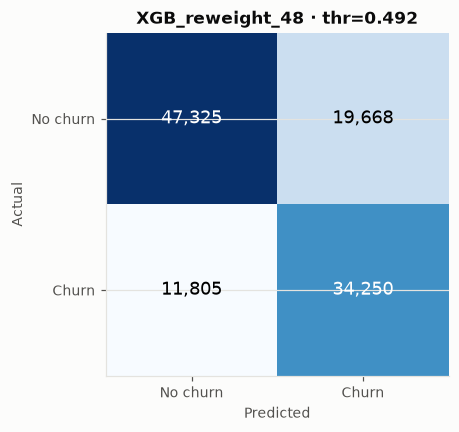

In [13]:
yhat = (proba_test >= THRESHOLD).astype(int)
cm   = confusion_matrix(y_test, yhat)

fig, ax = plt.subplots(figsize=(5, 4))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i,j]:,}', ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black', fontsize=12)
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['No churn', 'Churn'])
ax.set_yticklabels(['No churn', 'Churn'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
ax.set_title(f'XGB_reweight_48 · thr={THRESHOLD:.3f}', fontweight='bold')
plt.tight_layout()
fig.savefig(FIGS_DIR / 'confusion.png', dpi=150, bbox_inches='tight')
plt.show()

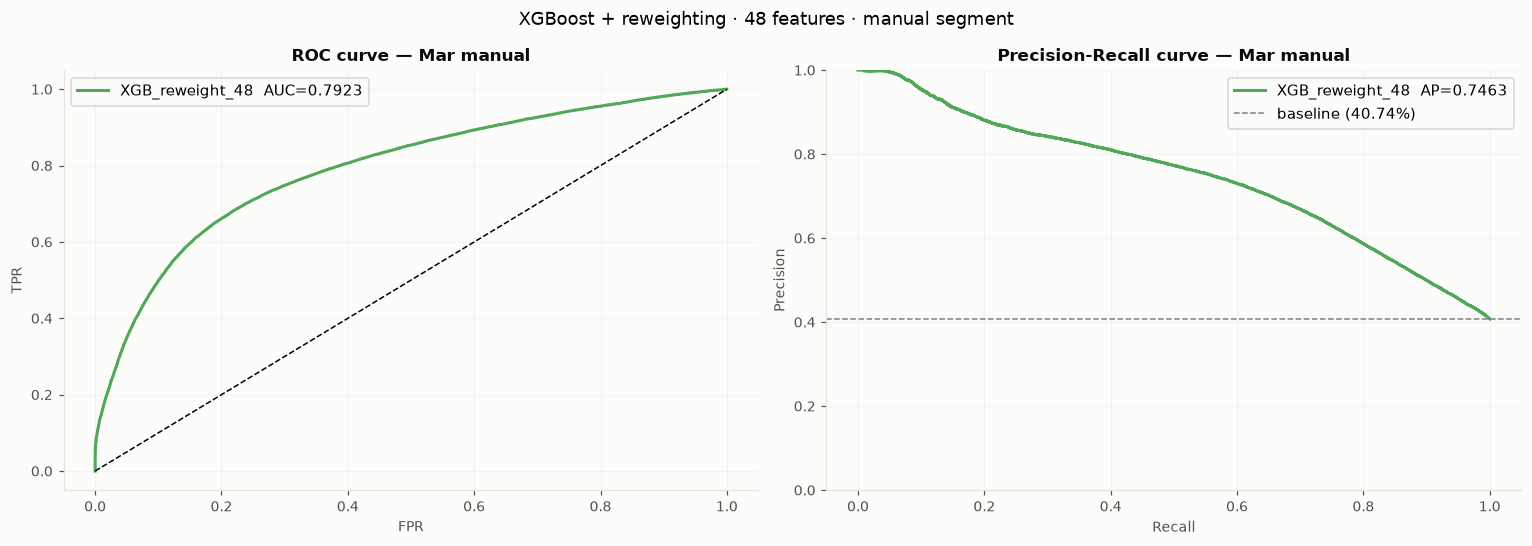

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
baseline_pr = float(y_test.mean())

fpr, tpr, _ = roc_curve(y_test, proba_test)
axes[0].plot(fpr, tpr, '#52a85a', lw=2,
             label=f'XGB_reweight_48  AUC={roc_auc_score(y_test, proba_test):.4f}')
axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[0].set_title('ROC curve — Mar manual', fontweight='bold')
axes[0].legend(fontsize=10); axes[0].grid(alpha=0.3)

p, r, _ = precision_recall_curve(y_test, proba_test)
axes[1].plot(r, p, '#52a85a', lw=2,
             label=f'XGB_reweight_48  AP={average_precision_score(y_test, proba_test):.4f}')
axes[1].axhline(baseline_pr, color='gray', ls='--', lw=1, label=f'baseline ({baseline_pr:.2%})')
axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall curve — Mar manual', fontweight='bold')
axes[1].set_ylim(0, 1); axes[1].legend(fontsize=10); axes[1].grid(alpha=0.3)

plt.suptitle('XGBoost + reweighting · 48 features · manual segment', fontsize=12)
plt.tight_layout()
fig.savefig(FIGS_DIR / 'roc_pr.png', dpi=150, bbox_inches='tight')
plt.show()

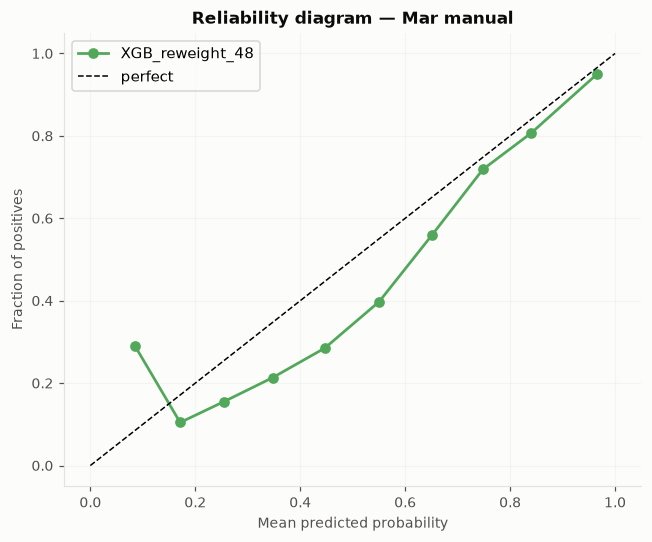

In [15]:
frac_pos, mean_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy='uniform')
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(mean_pred, frac_pos, 'o-', color='#52a85a', lw=1.8, label='XGB_reweight_48')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='perfect')
ax.set_xlabel('Mean predicted probability'); ax.set_ylabel('Fraction of positives')
ax.set_title('Reliability diagram — Mar manual', fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIGS_DIR / 'reliability.png', dpi=150, bbox_inches='tight')
plt.show()

## 10. Save artefact

```text
artifacts/sherlock_w1_manual_reweighting/
  models/
    XGB_reweight.joblib    — {preprocessor, model, best_iter}
  metrics/
    test_metrics.csv
    segment_metrics.csv
  run_config.json
```

In [16]:
ARTIFACTS_DIR = ROOT / 'w1' / 'artifacts' / 'sherlock_w1_manual_reweighting'
(ARTIFACTS_DIR / 'models').mkdir(parents=True, exist_ok=True)
(ARTIFACTS_DIR / 'metrics').mkdir(parents=True, exist_ok=True)

joblib.dump(
    {'preprocessor': prep_dev, 'model': xgb_rw_dev, 'best_iter': BEST_ITER},
    ARTIFACTS_DIR / 'models' / 'XGB_reweight.joblib',
)

test_metrics.to_csv(ARTIFACTS_DIR / 'metrics' / 'test_metrics.csv', index=False)
seg_df.to_csv(ARTIFACTS_DIR / 'metrics' / 'segment_metrics.csv', index=False)

run_cfg = {
    'seed': SEED,
    'features': FEATURES, 'n_features': len(FEATURES),
    'dropped_features': sorted(_DROP),
    'xgb_lr': XGB_LR, 'xgb_max_depth': XGB_MAX_DEPTH,
    'xgb_min_child_weight': XGB_MIN_CHILD_W,
    'xgb_colsample': XGB_COLSAMPLE, 'xgb_subsample': XGB_SUBSAMPLE,
    'xgb_early_stop': XGB_EARLY_STOP, 'best_iter': BEST_ITER,
    'plan_thr': PLAN_THR, 'w_churn': W_CHURN, 'w_nochurn': W_NOCHURN,
    'threshold': round(THRESHOLD, 5),
    'tune_log_loss': round(tune_ll, 5),
    'env': ENV,
}
(ARTIFACTS_DIR / 'run_config.json').write_text(json.dumps(run_cfg, indent=2))

print('Artefact saved in:', ARTIFACTS_DIR.resolve())

Artefact saved in: C:\Users\Usuario\Desktop\Materias\ML\Final Project\workshops\w1\artifacts\sherlock_w1_manual_reweighting
